# 03 — Biến thể A2: Adaptive Non-Maximal Suppression (ANMS)

ANMS **không thay detector Harris**. Ta dùng cùng một tập ứng viên Harris rồi thay bước chọn `N` điểm:

- Top-N: xếp theo response giảm dần.
- ANMS: xếp theo bán kính đến điểm gần nhất mạnh hơn đáng kể.

\[r_i = \min_{j: f(x_i)<c_{robust}f(x_j)}\|x_i-x_j\|\]

Điểm mạnh nhất có `r=∞`. Điểm yếu nhưng cô lập có thể có bán kính lớn và vẫn được giữ.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import matplotlib.pyplot as plt
from cv_bt2.corner import *
from cv_bt2.data.synthetic import *
from cv_bt2.visualization import plot_corners, plot_labels

OUT = ROOT / "outputs" / "figures"
OUT.mkdir(parents=True, exist_ok=True)
print("Project root:", ROOT)


Project root: /mnt/data/Computer_Vision_BT2


## 1. Ảnh thử nghiệm và tập ứng viên chung

Ảnh tổng hợp có nhiều góc mạnh ở nửa trái. Response thay đổi theo vị trí, tạo tình huống Top-N dễ ưu tiên nhóm điểm mạnh gần nhau. Phần so sánh dưới đây dùng cùng tập Harris và cùng số lượng `N`.

Tổng số ứng viên Harris: 285


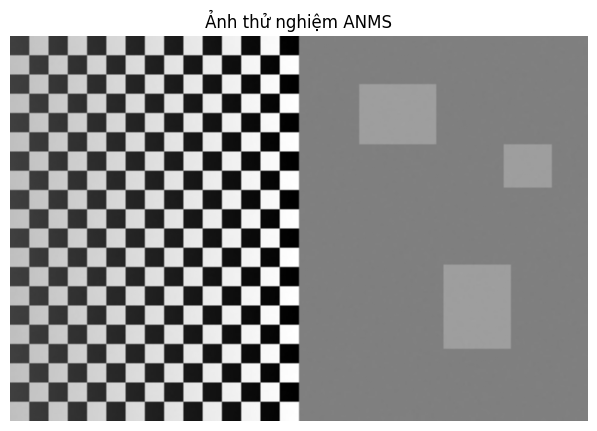

In [2]:
img = anms_scene()
points = harris_classic(img,sigma_i=1.5,sigma_d=1.0,thresh_rel=0.002)
print("Tổng số ứng viên Harris:",len(points))
plt.figure(figsize=(8,5)); plt.imshow(img,cmap="gray"); plt.title("Ảnh thử nghiệm ANMS"); plt.axis("off"); plt.show()

## 2. So sánh Top-N và ANMS

`grid_occupancy` chia ảnh thành lưới 8×8 và đo tỉ lệ ô có ít nhất một điểm. Giá trị càng cao nghĩa là tập điểm phủ được nhiều khu vực ảnh hơn (không đồng nghĩa trực tiếp với độ chính xác nhận dạng).

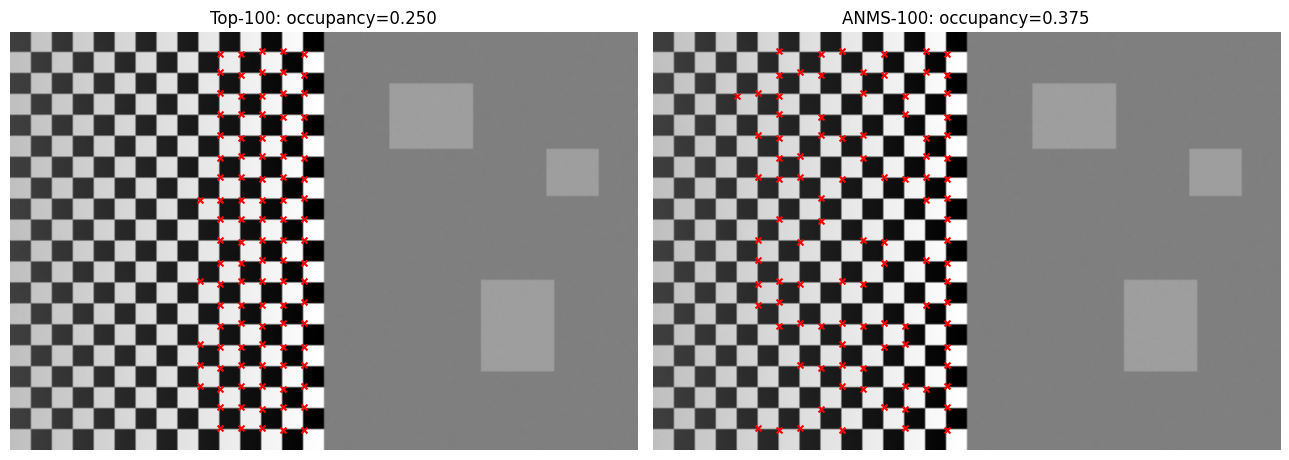

Cùng N=100: Top-N occupancy=0.250; ANMS occupancy=0.375


In [3]:
N=100; c_robust=0.9
top_points=top_n(points,N)
anms_points=anms(points,N,c_robust=c_robust)
occ_top=grid_occupancy(top_points,img.shape,grid_size=8)
occ_anms=grid_occupancy(anms_points,img.shape,grid_size=8)
fig,ax=plt.subplots(1,2,figsize=(13,5))
plot_corners(img,top_points,ax=ax[0],title=f"Top-{N}: occupancy={occ_top:.3f}")
plot_corners(img,anms_points,ax=ax[1],title=f"ANMS-{N}: occupancy={occ_anms:.3f}")
plt.tight_layout(); plt.show()
print(f"Cùng N={N}: Top-N occupancy={occ_top:.3f}; ANMS occupancy={occ_anms:.3f}")

## 3. Quét `c_robust`

`c_robust` càng nhỏ thì một điểm khác phải mạnh hơn nhiều mới được quyền ức chế điểm đang xét. Khi `c_robust` tiến gần 1, nhiều điểm có response hơi lớn hơn có thể trở thành đối thủ ức chế. Theo đề, cần xem cả độ phủ và tập điểm thay đổi.

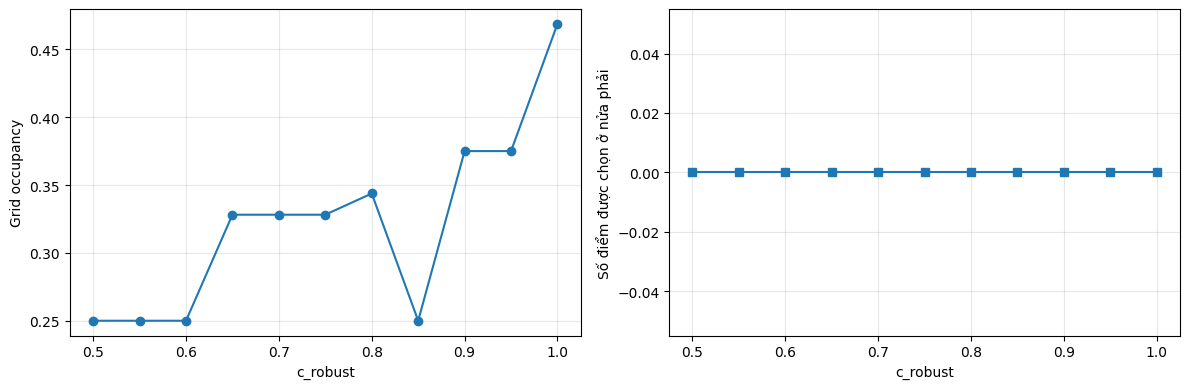

[(np.float64(0.5), np.float64(0.25), 0), (np.float64(0.55), np.float64(0.25), 0), (np.float64(0.6), np.float64(0.25), 0), (np.float64(0.65), np.float64(0.328), 0), (np.float64(0.7), np.float64(0.328), 0), (np.float64(0.75), np.float64(0.328), 0), (np.float64(0.8), np.float64(0.344), 0), (np.float64(0.85), np.float64(0.25), 0), (np.float64(0.9), np.float64(0.375), 0), (np.float64(0.95), np.float64(0.375), 0), (np.float64(1.0), np.float64(0.469), 0)]


In [4]:
c_values=np.linspace(0.5,1.0,11)
occupancies=[]; right_counts=[]
for c in c_values:
    selected=anms(points,N,c_robust=float(c))
    occupancies.append(grid_occupancy(selected,img.shape,8))
    right_counts.append(int(np.count_nonzero(selected[:,1] >= img.shape[1]//2)))
fig,ax=plt.subplots(1,2,figsize=(12,4))
ax[0].plot(c_values,occupancies,marker="o"); ax[0].set_xlabel("c_robust")
ax[0].set_ylabel("Grid occupancy"); ax[0].grid(alpha=.3)
ax[1].plot(c_values,right_counts,marker="s"); ax[1].set_xlabel("c_robust")
ax[1].set_ylabel("Số điểm được chọn ở nửa phải"); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()
print(list(zip(np.round(c_values,2),np.round(occupancies,3),right_counts)))

## 4. Quét số điểm N

Khi N tăng, cả hai phương pháp thường phủ thêm ô lưới. Điều đáng quan sát là với cùng N, ANMS có thể trải các điểm ra rộng hơn do xếp theo bán kính ức chế thay vì chỉ theo response.

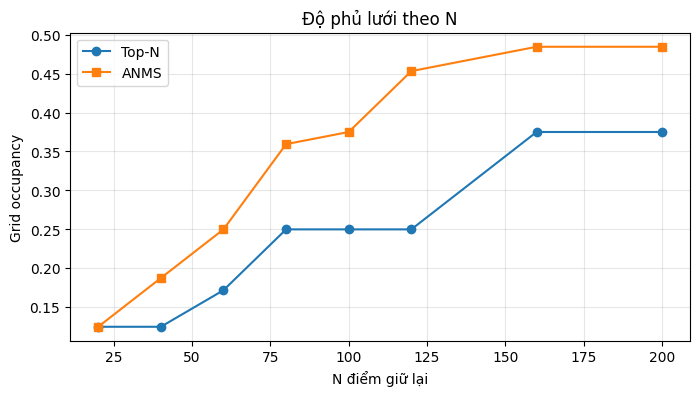

In [5]:
n_values=[20,40,60,80,100,120,160,200]
top_occ=[]; anms_occ=[]
for n in n_values:
    top_occ.append(grid_occupancy(top_n(points,n),img.shape,8))
    anms_occ.append(grid_occupancy(anms(points,n,0.9),img.shape,8))
plt.figure(figsize=(8,4)); plt.plot(n_values,top_occ,marker="o",label="Top-N")
plt.plot(n_values,anms_occ,marker="s",label="ANMS")
plt.xlabel("N điểm giữ lại"); plt.ylabel("Grid occupancy")
plt.title("Độ phủ lưới theo N"); plt.grid(alpha=.3); plt.legend(); plt.show()

## 5. Kết luận và câu hỏi ôn tập

1. ANMS có phát hiện góc mới không? **Không**; nó chọn lại từ tập ứng viên Harris.
2. Vì sao phải so sánh cùng N? Để kiểm soát số điểm, tránh nhầm cải thiện độ phủ với việc đơn giản giữ nhiều điểm hơn.
3. Vì sao điểm response thấp vẫn có thể được chọn? Vì nó ở xa các điểm đủ mạnh để ức chế nên có bán kính `r_i` lớn.
4. `c_robust=0.9` đòi hỏi điểm ức chế phải mạnh hơn đáng kể; giá trị này nên được khảo sát chứ không xem là hằng số đúng cho mọi ảnh.